# Case Study 18 — "40% Better Than the Bureau" — on What Metric? Comparing an In-House Credit Score with a Generic Bureau Score

**Priority:** ★★ Good to have · **Reference:** Case Study 18 — *Axis Bank: in-house credit scores that beat generic bureau models* (`indian_fintech_data_science_case_studies.md`)
**Audience:** Chief Risk Officer, Head of Retail Credit, Model Validation, Business heads (cards & personal loans)
**Data:** ⚠️ **SYNTHETIC** (D-18-01). Bank data are confidential; this is a calibrated simulation.
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs18_custom_score_vs_bureau.ipynb`

## 0. Executive Summary for Business

*(Synthetic data built on Axis Bank's documented claim; the source does not say which metric improved by 40%. Written after the analysis.)*

- **The question:** is the bank's in-house score really "more than 40% better" than the bureau score, and what does that mean in defaults and approvals?
- **The same two scores can be "6% better" or "100% better", depending on the metric.** Out-of-time, the in-house score (bank transaction data + bureau) improves on the bureau score alone by:

| Metric | Improvement (95% CI) |
|---|---|
| AUC | +6.5% |
| Bad rate at a 70% approval rate | −11% |
| Bads caught in the riskiest 10% | +18% |
| **Gini** | **+32%** (24–41%) |
| **KS** | **+41%** (29–54%), the documented range |
| Approvals at a 3.5% bad rate | +50% |
| Brier skill | +100% |

  All are statistically significant. **"40% better" is a true statement here only for KS.** Without the metric it is not a claim a credit committee can use.
- **What the improvement means:**
  - At today's 70% approval rate, the bad rate falls from **4.34% to 3.86%**.
  - At the same risk, approvals rise from **70.5% to 81.3%**.
- **Who changes:** the swap set is 11.7% of applicants each way. Customers the new score newly approves default **5.6%** of the time, vs **8.5%** for those it newly rejects (p ≈ 7e-10). The new score also ranks **no-hit applicants** the bureau cannot score (AUC 0.61 vs 0.50).
- **The two data sources are complements:** internal data alone (AUC 0.620) are no better than the bureau alone (0.628), but together they are clearly better (0.668). The advantage is stable across all six test months (no decay; PSI 0.000).
- **₹ impact (1 lakh applications/month):**
  - Either ≈ **₹40 crore/year of credit losses avoided** (CI ₹26–53 crore) at the same approval rate.
  - Or ≈ ₹20 crore/year of extra profit from approving 10.8 pp more customers at the same risk.
- **I recommend:**
  - Adopt the in-house score as champion for existing-customer lending, after a champion–challenger run on 5–10% of decisions.
  - Report its benefit as "bad rate at fixed approval" and "approvals at fixed bad rate", with Gini and KS stated explicitly, never as an unlabelled "X% better".

## 1. The Problem in Simple English

Axis Bank says its own machine-learning credit models are "**more than 40% better**" than generic bureau scores. That sounds impressive, but **40% better at what?**
- Ranking risky customers above safe ones (Gini)?
- The biggest gap between good and bad customers (KS)?
- Fewer defaults at the same approval rate?
- More approvals at the same default rate?

The same two models can be "15% better" on one measure and "60% better" on another.

A bank's advantage is data the bureau does not have: salary credits, balance trends, bounced payments, internal collections history. This notebook builds a bureau-only score and an in-house score on synthetic data. It shows how much each metric says the in-house score improves, and turns the improvement into what a credit committee cares about: **defaults avoided and customers approved**. It also checks **who** the new score approves differently (the "swap set").

## 2. Reference from the Case File

### (a) What Axis Bank did — *documented*

| Item | Documented fact (quoted from the reference file) |
|---|---|
| Problem | "Replace intuition-based credit strategy with data-driven decisions"; on-premises setup could not support ad-hoc ML |
| Question | "Can the bank's own data predict credit risk better than generic bureau scores, and support pre-approved, database-driven lending?" |
| Data | 750 TB from Oracle Exadata and other sources; application, transaction and collections data; **2,000** credit-model attributes |
| ML / metric | "ML-based credit models"; "**More than 40% improvement**" over generic bureau models; **metric (Gini / KS / other) ND** |
| Decision / impact | "**66% of personal loans**" via database-driven programmes; "**79% of new credit card sourcing** via data-driven strategy" |
| Tech | Cloudera Machine Learning / Data Engineering / Data Warehouse (data mesh) |

**Source:** Cloudera customer story, Axis Bank (undated) — https://www.cloudera.com/customers/axis-bank.html (related, older: https://www.sas.com/en_in/customers/axis-bank-india-capitalize-data.html)

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| Data | 150,000 applications by existing customers over 18 months (PL + cards). Risk has a **bureau-visible** part and an **internal-only** part. 68% thick bureau files, 20% thin, 12% no hit. 13 internal features. Target: 90+ DPD in 12 months (≈ 5.7%). |
| Models | (0) bureau score alone; (1) bureau + application data (logistic); (2) **in-house**: internal + bureau (gradient boosting); (3) internal only |
| Statistics added | Out-of-time AUC/Gini/KS with DeLong; **relative improvement on 7 metrics with paired bootstrap CIs**; bad rate at a fixed approval rate and approvals at a fixed bad rate; **swap-set analysis** with Wilson CIs; results by bureau depth; calibration; month-by-month Gini stability and PSI |

### (c) How the industry uses this

Every large Indian bank and NBFC now builds in-house "application + behaviour" scores on top of bureau scores (HDFC P27 in Case 17, ICICI, Kotak, Bajaj Finance), and bureaus sell custom scores too. The **champion–challenger** comparison here (same population, out-of-time, business metrics, swap sets) is the standard validation a model-risk team requires before a new score replaces the old one.

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | Should we replace the bureau score with our in-house score for pre-approved and data-driven lending? What do we gain? |
| Analytical | How much better does the in-house score rank and select applicants out-of-time, measured on several metrics, and what does that mean for defaults and approvals? |

**Hypotheses**
- **H1:** H0: AUC(in-house) = AUC(bureau) (DeLong, out-of-time). Also vs bureau + application (Holm across comparisons).
- **H2:** H0: bad rate among approved applicants at a **70% approval rate** is the same (paired bootstrap).
- **H3 (swap set):** H0: applicants approved by the in-house score but rejected by the bureau ("swap-in") have the same bad rate as those approved by the bureau but rejected by the in-house score ("swap-out").

**Primary business metric:** bad rate at a fixed 70% approval rate. **Secondary:** approval rate at a fixed 3.5% bad rate; Gini; KS. **Design:** train months 1–12 → **test months 13–18**.

In [1]:
import sys, warnings, importlib, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import rankdata
import statsmodels.api as sm
from sklearn.ensemble import HistGradientBoostingClassifier as HGB
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, brier_score_loss
from statsmodels.stats.proportion import proportion_confint, proportions_ztest
from statsmodels.stats.multitest import multipletests

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public bank data with bureau score + internal transaction features + outcomes | **None.** Bureau scores are licensed; internal data are confidential. |
| **Decision** | Synthetic applications with a bureau-visible and an internal-only risk component (D-18-01) |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs18.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 18 (Axis Bank-style in-house credit score vs generic bureau score)
=======================================================================================================
THIS DATA IS SYNTHETIC. Bank application, transaction and collections data are confidential.

Existing bank customers who applied for (or were offered) a personal loan or credit card over 18 months.
Two information sources see DIFFERENT parts of a customer's credit risk:
  * the generic BUREAU score sees repayment history across all lenders (blank / thin for some customers)
  * the bank's INTERNAL data see salary credits, balance trends, account vintage, bounces, internal
    collections history, product holdings and spending - things a bureau never sees
Target: bad = 90+ DPD within 12 months on the new product.

Calibration anchors (reference file, Case Study 18): "2,000" credit-model attributes; "More than 40%
improvement" over generic bureau models (metric ND); 66% of PL and 79% of new card sourcing via
data-driven / pre-approved programmes. Rates are our assumptions (decision.md D-18-02). Hidden truth "_".

Output: data/cs18/applications.csv.gz
"""
import os
import numpy as np
import pandas as pd
from scipy.special import expit

SEED = 42


def generate(seed=SEED, n=150_000):
    rng = np.random.default_rng(seed)
    month = rng.integers(0, 18, n)
    zb = rng.normal(0, 1, n)                      # risk component visible to the bureau (cross-lender repayment)
    zi = rng.normal(0, 1, n)                      # risk component visible only in internal data (cash flow, stability)
    product = rng.choice(["personal_loan", "credit_card"], n, p=[0.45, 0.55])
    depth = rng.choice(["thick", "thin", "no_hit"], n, p=[0.68, 0.20, 0.12])
    noise_b = np.where(depth == "thick", 35, np.where(depth == "thin", 80, np.nan))
    bureau = np.where(depth == "no_hit", np.nan, np.clip(np.round(735 + 55 * zb + rng.normal(0, 1, n) * np.nan_to_num(noise_b)), 300, 900))
    salary = np.exp(rng.normal(np.log(48000), 0.55, n) + 0.12 * zi)
    sal_credit_regular = np.clip(rng.beta(6 + 2 * zi.clip(-2, 2), 2, n), 0, 1)
    bal_trend = rng.normal(0.02 * zi, 0.08, n)                                    # 6-month balance slope (share of salary)
    casa_vintage = np.clip(rng.gamma(2.2, 3.0, n) + 0.6 * zi, 0.2, 30)
    bounces_12m = rng.poisson(np.exp(-1.4 - 0.7 * zi))
    internal_dpd = rng.poisson(np.exp(-2.2 - 0.6 * zi - 0.3 * zb))
    n_products = 1 + rng.poisson(np.exp(0.2 + 0.15 * zi))
    card_spend_ratio = np.clip(rng.gamma(2, 0.12, n) * np.exp(-0.1 * zi), 0.01, 2.5)
    cash_withdraw_share = np.clip(rng.beta(2, 6, n) - 0.04 * zi, 0, 1)
    emi_to_salary = np.clip(rng.gamma(2, 0.1, n) * np.exp(-0.15 * zi - 0.1 * zb), 0, 1.5)
    age = np.clip(rng.normal(34, 8, n), 21, 65).round()
    lg = -3.25 - 0.62 * zb - 0.62 * zi + 0.2 * (product == "credit_card") + 0.6 * np.clip(emi_to_salary - 0.4, 0, None) + 0.04 * (month >= 12) * rng.normal(1, 0.2, n)
    p_bad = expit(lg); bad = (rng.random(n) < p_bad).astype(int)
    df = pd.DataFrame({"app_id": [f"A{i:07d}" for i in range(n)], "app_month": month + 1, "product": product, "bureau_depth": depth, "bureau_score": bureau,
                       "monthly_salary": np.round(salary, -2), "salary_credit_regularity": sal_credit_regular.round(3), "balance_trend_6m": bal_trend.round(4),
                       "casa_vintage_years": casa_vintage.round(1), "bounces_12m": bounces_12m, "internal_dpd_events_24m": internal_dpd, "n_products_held": n_products,
                       "card_spend_to_salary": card_spend_ratio.round(3), "cash_withdrawal_share": cash_withdraw_share.round(3), "emi_to_salary": emi_to_salary.round(3),
                       "age": age, "bad_90dpd_12m": bad, "_p_bad": p_bad, "_zb": zb, "_zi": zi})
    # data-quality defects
    df.loc[df.sample(n=600, random_state=seed).index, "bureau_score"] = 0                  # "0" sentinel for bureau timeouts
    df.loc[df.sample(frac=0.015, random_state=seed + 1).index, "balance_trend_6m"] = np.nan
    df = pd.concat([df, df.sample(n=500, random_state=seed + 2)], ignore_index=True)
    return df


if __name__ == "__main__":
    here = os.path.dirname(os.path.abspath(__file__)); os.makedirs(os.path.join(here, "cs18"), exist_ok=True)
    d = generate(); d.to_csv(os.path.join(here, "cs18", "applications.csv.gz"), index=False)
    dd = d.drop_duplicates("app_id"); print(len(dd), "applications | bad rate", dd.bad_90dpd_12m.mean().round(4)); print(dd.groupby("bureau_depth").bad_90dpd_12m.mean().round(4).to_dict())

Overwriting data/generate_cs18.py


In [3]:
os.makedirs("data/cs18", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs18 as gen; importlib.reload(gen)
raw = gen.generate(seed=SEED); raw.to_csv("data/cs18/applications.csv.gz", index=False)
print(f"{len(raw):,} rows | {raw.app_id.nunique():,} unique applications")
raw.drop(columns=[c for c in raw.columns if c.startswith("_")]).sample(3, random_state=SEED).T

150,500 rows | 150,000 unique applications


,88847,117203,147661
app_id,A0088847,A0117203,A0147661
app_month,18,6,15
product,credit_card,credit_card,personal_loan
bureau_depth,thick,thick,thick
bureau_score,795.0000,771.0000,667.0000
monthly_salary,"54,200.0000","33,700.0000","40,900.0000"
salary_credit_regularity,0.8490,0.7650,0.6270
balance_trend_6m,-0.0384,-0.0739,0.0139
casa_vintage_years,5.0000,9.2000,1.8000
bounces_12m,1,0,1


| Parameter | Value | Basis |
|---|---|---|
| Applications | 150,000 over 18 months; PL 45% / cards 55% | Our assumption |
| Risk structure | Equal weight on a bureau-visible component (cross-lender repayment) and an internal-only component (cash flow, stability) | Our assumption: the reason in-house data help |
| Bureau | 68% thick (precise), 20% thin (noisy), 12% no hit | Typical Indian bank applicant mix |
| Internal features | Salary, salary-credit regularity, balance trend, CASA vintage, bounces, internal DPD, products held, card spend, cash withdrawals, EMI-to-salary, age | **Documented** application/transaction/collections data; "2,000 attributes" condensed |
| Target | 90+ DPD in 12 months ≈ 5.7% | Our assumption |
| DQ issues | 500 duplicate rows; 600 bureau scores coded 0 (timeouts); 1.5% missing balance trend | Built-in messiness |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("app_id, app_month, product", "Application, month 1–18, PL or card"), ("bureau_depth, bureau_score", "thick / thin / no_hit; generic bureau score (blank for no-hit)"),
    ("monthly_salary, salary_credit_regularity, balance_trend_6m, casa_vintage_years", "Internal: income and stability"),
    ("bounces_12m, internal_dpd_events_24m", "Internal: bounced payments, internal collections history"), ("n_products_held, card_spend_to_salary, cash_withdrawal_share, emi_to_salary, age", "Internal: relationship and behaviour"),
    ("bad_90dpd_12m", "Target: 90+ DPD within 12 months"), ("_p_bad, _zb, _zi", "HIDDEN: true PD, bureau-visible and internal-only risk"),
], columns=["field(s)", "meaning"])
dd.to_csv("data/cs18/data_dictionary.csv", index=False); dd

,field(s),meaning
0,"app_id, app_month, product","Application, month 1–18, PL or card"
1,"bureau_depth, bureau_score",thick / thin / no_hit; generic bureau score (b...
2,"monthly_salary, salary_credit_regularity, bala...",Internal: income and stability
3,"bounces_12m, internal_dpd_events_24m","Internal: bounced payments, internal collectio..."
4,"n_products_held, card_spend_to_salary, cash_wi...",Internal: relationship and behaviour
5,bad_90dpd_12m,Target: 90+ DPD within 12 months
6,"_p_bad, _zb, _zi","HIDDEN: true PD, bureau-visible and internal-o..."


## 5. Data Quality Checks

In [5]:
df = raw.copy()
checks = {"duplicate app_id": int(df.app_id.duplicated().sum()), "bureau_score = 0 (timeout sentinel)": int((df.bureau_score == 0).sum()),
          "bureau score present for no-hit": int(((df.bureau_depth == "no_hit") & df.bureau_score.notna() & (df.bureau_score > 0)).sum()),
          "balance trend missing": int(df.balance_trend_6m.isna().sum())}
print(pd.Series(checks, name="rows").to_string())
df = df.drop_duplicates("app_id").reset_index(drop=True)
df["bureau_missing"] = ((df.bureau_score == 0) | df.bureau_score.isna()).astype(int); df.loc[df.bureau_score == 0, "bureau_score"] = np.nan
df["bal_missing"] = df.balance_trend_6m.isna().astype(int); df["balance_trend_6m"] = df.balance_trend_6m.fillna(0)
df["is_card"] = (df["product"] == "credit_card").astype(int); df["depth_c"] = df.bureau_depth.map({"thick": 0, "thin": 1, "no_hit": 2})
TR, TE = (df.app_month <= 12).values, (df.app_month >= 13).values
print(f"\nClean: {len(df):,} applications | bad rate {df.bad_90dpd_12m.mean():.2%} | train {TR.sum():,} · out-of-time test {TE.sum():,} ({df.bad_90dpd_12m[TE].sum():,} bads)")

duplicate app_id                        500
bureau_score = 0 (timeout sentinel)     603
bureau score present for no-hit           0
balance trend missing                  2257



Clean: 150,000 applications | bad rate 5.67% | train 99,857 · out-of-time test 50,143 (2,836 bads)


**Observation:** we removed **500 duplicate applications** and converted **603 bureau scores of 0** (a timeout sentinel, not a real score) to missing with a flag, alongside the genuine no-hits. **2,257 missing balance trends** (1.5%) are set to 0 with a missing flag. No no-hit applicant has a score. Clean: **150,000 applications, 5.67% bad**; 99,857 for training (months 1–12) and **50,143 out-of-time** test applications (months 13–18, 2,836 bads).

## 6. Exploratory Data Analysis

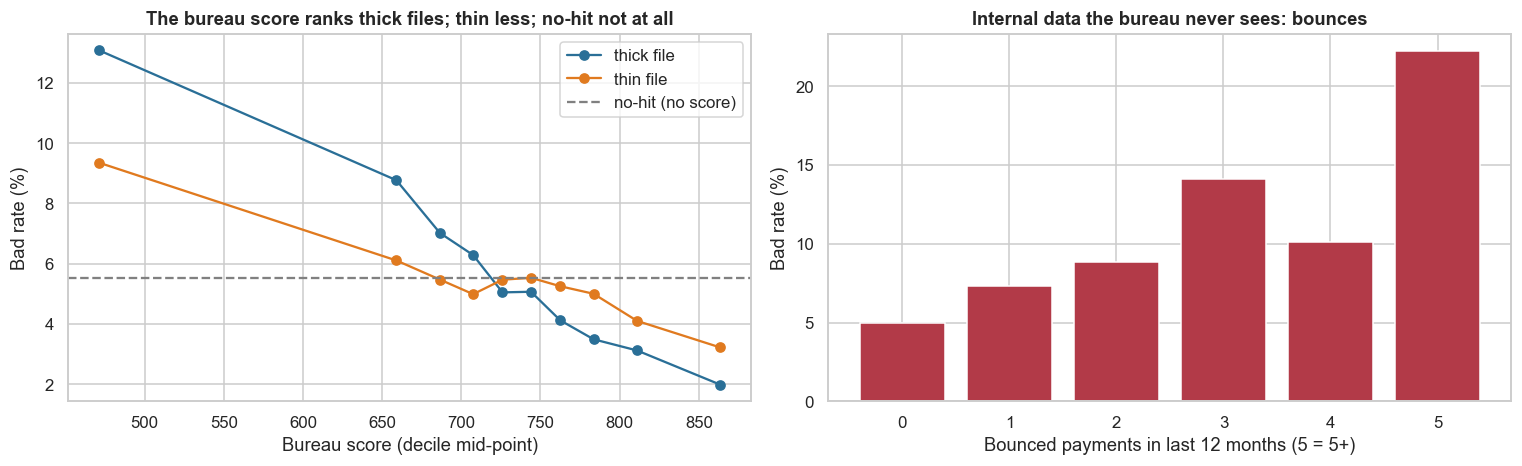

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
b = df[df.bureau_score.notna()].copy(); b["band"] = pd.qcut(b.bureau_score, 10)
for dpt, c_ in (("thick", "#2a6f97"), ("thin", "#e07a1f")):
    g = b[b.bureau_depth == dpt].groupby("band").bad_90dpd_12m.mean() * 100; axes[0].plot([iv.mid for iv in g.index], g.values, "o-", color=c_, label=f"{dpt} file")
axes[0].axhline(df.loc[df.bureau_depth == "no_hit", "bad_90dpd_12m"].mean() * 100, color="grey", ls="--", label="no-hit (no score)")
axes[0].set_xlabel("Bureau score (decile mid-point)"); axes[0].set_ylabel("Bad rate (%)"); axes[0].set_title("The bureau score ranks thick files; thin less; no-hit not at all"); axes[0].legend()
for f_, ax_lab in (("bounces_12m", "bounces in 12 months"), ):
    g = df.groupby(df[f_].clip(upper=5)).bad_90dpd_12m.mean() * 100
    axes[1].bar(g.index.astype(str), g.values, color="#b23a48")
axes[1].set_xlabel("Bounced payments in last 12 months (5 = 5+)"); axes[1].set_ylabel("Bad rate (%)"); axes[1].set_title("Internal data the bureau never sees: bounces")
plt.tight_layout(); plt.show()

**Takeaway:** - **Left:** the bureau score ranks **thick** files well, ranks **thin** files less steeply, and gives **no information at all for no-hit** applicants (the grey line, a flat 5.5% bad rate the bureau cannot split). That is 12% of applicants the bureau cannot rank, and 20% it ranks poorly.
- **Right:** a signal only the bank can see. Customers with bounced payments in the last year default far more often (≈ 4% with none vs well above 10% with 4–5+). The bureau never sees an ECS/NACH bounce on a savings account.

## 7. Statistical Analysis (core section)

### 7.1 Four scores, out-of-time

**(a) Why out-of-time?** A new score must work on *future* applicants. We train on months 1–12 and test on months 13–18. The four scorers:
1. **Bureau score alone:** the "generic bureau model". No-hit applicants get the median, so it cannot rank them.
2. **Bureau + application:** logistic on bureau score, depth, product, age and salary, i.e., what a bank without transaction data could build.
3. **In-house (internal + bureau):** gradient boosting on all features. This is the challenger.
4. **Internal only:** gradient boosting without the bureau. How much do internal data alone carry?

AUC with **DeLong** (Holm vs the bureau score), Gini = 2·AUC − 1, KS.

In [7]:
INT = ["monthly_salary", "salary_credit_regularity", "balance_trend_6m", "bal_missing", "casa_vintage_years", "bounces_12m", "internal_dpd_events_24m", "n_products_held",
       "card_spend_to_salary", "cash_withdrawal_share", "emi_to_salary", "age", "is_card"]
BUR = ["bureau_score", "bureau_missing", "depth_c"]
y = df.bad_90dpd_12m.values; yte = y[TE]
def hgb(): return HGB(max_iter=300, learning_rate=0.06, max_leaf_nodes=31, random_state=SEED)
Xapp = df[["bureau_score", "bureau_missing", "depth_c", "is_card", "age"]].copy(); Xapp["bureau_score"] = Xapp.bureau_score.fillna(df.bureau_score.median()); Xapp["l_sal"] = np.log(df.monthly_salary)
P = {"0 bureau score alone": -df.bureau_score.fillna(df.bureau_score.median()).values[TE],
     "1 bureau + application (logistic)": make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)).fit(Xapp[TR], y[TR]).predict_proba(Xapp[TE])[:, 1],
     "2 in-house: internal + bureau (GBM)": hgb().fit(df.loc[TR, INT + BUR], y[TR]).predict_proba(df.loc[TE, INT + BUR])[:, 1],
     "3 internal only (GBM)": hgb().fit(df.loc[TR, INT], y[TR]).predict_proba(df.loc[TE, INT])[:, 1]}
def delong(y, preds):
    y = np.asarray(y); pos, neg = preds[:, y == 1], preds[:, y == 0]; m, n = pos.shape[1], neg.shape[1]
    tx = np.array([rankdata(p) for p in pos]); ty = np.array([rankdata(q) for q in neg]); tz = np.array([rankdata(np.r_[p, q]) for p, q in zip(pos, neg)])
    aucs = tz[:, :m].sum(1) / m / n - (m + 1) / 2 / n; v01 = (tz[:, :m] - tx) / n; v10 = 1 - (tz[:, m:] - ty) / m
    return aucs, np.atleast_2d(np.cov(v01)) / m + np.atleast_2d(np.cov(v10)) / n
def ks(y, p): o = np.argsort(-p); yy = y[o]; return np.max(np.abs(np.cumsum(yy) / yy.sum() - np.cumsum(1 - yy) / (1 - yy).sum()))
names = list(P); A_, C_ = delong(yte, np.vstack([P[n] for n in names]))
mt = pd.DataFrame({"AUC": A_, "Gini": 2 * A_ - 1, "KS": [ks(yte, P[n]) for n in names]}, index=names)
pv = [np.nan] + [2 * stats.norm.sf(abs(A_[i] - A_[0]) / np.sqrt(C_[i, i] + C_[0, 0] - 2 * C_[0, i])) for i in range(1, 4)]
mt["Δ AUC vs bureau"] = A_ - A_[0]; mt["DeLong p vs bureau"] = pv; mt.loc[names[1:], "p_holm"] = multipletests(pv[1:], method="holm")[1]
d23 = 2 * stats.norm.sf(abs(A_[2] - A_[1]) / np.sqrt(C_[2, 2] + C_[1, 1] - 2 * C_[1, 2]))
print(f"In-house vs bureau + application: ΔAUC = {A_[2] - A_[1]:+.4f}, DeLong p = {d23:.2g}")
mt.round(4)

In-house vs bureau + application: ΔAUC = +0.0324, DeLong p = 1.1e-13


,AUC,Gini,KS,Δ AUC vs bureau,DeLong p vs bureau,p_holm
0 bureau score alone,0.6276,0.2552,0.1757,0.0000,NaN,NaN
1 bureau + application (logistic),0.6358,0.2715,0.1900,0.0082,0.0007,0.0014
2 in-house: internal + bureau (GBM),0.6682,0.3364,0.2483,0.0406,0.0000,0.0000
3 internal only (GBM),0.6196,0.2391,0.1712,-0.0080,0.2915,0.2915


**(c)/(f) Observation:** - **The bureau score alone:** AUC 0.628 (Gini 0.255, KS 0.176).
- **Bureau + application data** (logistic) adds a little: +0.008 AUC (Holm p = 0.001).
- **The in-house score** (internal + bureau, gradient boosting) reaches **AUC 0.668** (Gini 0.336, KS 0.248): **+0.041 vs the bureau** (Holm p < 0.0001) and +0.032 vs bureau + application (p ≈ 1e-13).
- **Internal data alone** (0.620) do *not* beat the bureau (p = 0.29).
- **(f) Business meaning:** the bank's edge comes from **combining** its own data with the bureau, not replacing the bureau. Absolute AUCs are modest because this is a pre-screened customer base.

### 7.2 "40% better" — the same models on seven metrics

We compute the in-house score's **relative improvement over the bureau score** on seven metrics, each with a **paired bootstrap 95% CI** (1,000 resamples of test applicants):

| Metric | "Better" means |
|---|---|
| Gini | (G₁ − G₀)/G₀ |
| AUC | (A₁ − A₀)/A₀ |
| KS | (KS₁ − KS₀)/KS₀ |
| Bad rate at 70% approval | reduction (B₀ − B₁)/B₀ |
| Approval at 3.5% bad rate | (Ap₁ − Ap₀)/Ap₀ |
| Bads captured in the riskiest 10% | (C₁ − C₀)/C₀ |
| Brier skill vs base rate | (BS₀ − BS₁)/BS₀ (bureau converted to a probability by logistic calibration on training data) |

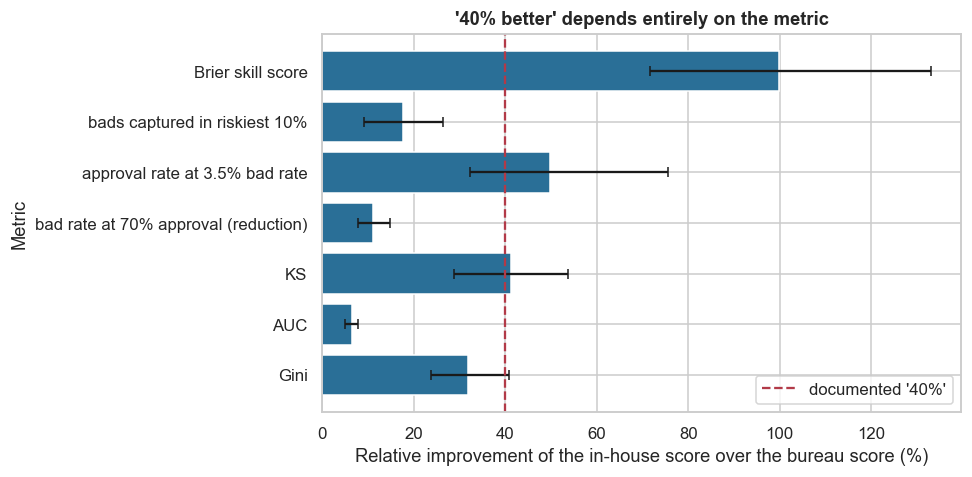

,bureau,in-house
Gini,0.2552,0.3364
AUC,0.6276,0.6682
KS,0.1757,0.2483
bad rate at 70% approval (reduction),0.0434,0.0386
approval rate at 3.5% bad rate,0.4018,0.6019
bads captured in riskiest 10%,0.2024,0.2380
Brier skill score,NaN,NaN


,in-house improvement over bureau,CI low,CI high
Gini,0.3184,0.2389,0.4078
AUC,0.0647,0.0503,0.0791
KS,0.4131,0.2883,0.5377
bad rate at 70% approval (reduction),0.1121,0.0792,0.1478
approval rate at 3.5% bad rate,0.4981,0.3230,0.7562
bads captured in riskiest 10%,0.1760,0.0924,0.2634
Brier skill score,0.9995,0.7171,1.3305


In [8]:
APPROVE, TARGET = 0.70, 0.035
def bad_at_approval(y, p, a=APPROVE): k = int(a * len(y)); return y[np.argsort(p)[:k]].mean()
def approval_at_bad(y, p, t=TARGET):
    cb = np.cumsum(y[np.argsort(p)]) / np.arange(1, len(y) + 1); ok = np.where(cb <= t)[0]; return (ok.max() + 1) / len(y) if len(ok) else 0.0
def capture(y, p, q=0.10): k = int(q * len(y)); return y[np.argsort(-p)[:k]].sum() / y.sum()
cal0 = LogisticRegression().fit(-df.bureau_score.fillna(df.bureau_score.median()).values[TR].reshape(-1, 1), y[TR])
p0_prob = cal0.predict_proba(P["0 bureau score alone"].reshape(-1, 1))[:, 1]; p2 = P["2 in-house: internal + bureau (GBM)"]
def metrics(y, a, b, ap, bp):
    A0, A1 = roc_auc_score(y, a), roc_auc_score(y, b); bs_ref = y.mean() * (1 - y.mean())
    return np.array([(2 * A1 - 1) / (2 * A0 - 1) - 1, A1 / A0 - 1, ks(y, b) / ks(y, a) - 1, 1 - bad_at_approval(y, b) / bad_at_approval(y, a),
                     approval_at_bad(y, b) / max(approval_at_bad(y, a), 1e-9) - 1, capture(y, b) / capture(y, a) - 1,
                     (bs_ref - brier_score_loss(y, bp)) / (bs_ref - brier_score_loss(y, ap)) - 1])
MN = ["Gini", "AUC", "KS", "bad rate at 70% approval (reduction)", "approval rate at 3.5% bad rate", "bads captured in riskiest 10%", "Brier skill score"]
point = metrics(yte, P["0 bureau score alone"], p2, p0_prob, p2)
bs = np.array([metrics(yte[i], P["0 bureau score alone"][i], p2[i], p0_prob[i], p2[i]) for i in (RNG.integers(0, len(yte), len(yte)) for _ in range(1000))])
rel = pd.DataFrame({"in-house improvement over bureau": point, "CI low": np.percentile(bs, 2.5, axis=0), "CI high": np.percentile(bs, 97.5, axis=0)}, index=MN)
lv = pd.DataFrame({"bureau": [2 * A_[0] - 1, A_[0], ks(yte, P[names[0]]), bad_at_approval(yte, P[names[0]]), approval_at_bad(yte, P[names[0]]), capture(yte, P[names[0]]), np.nan],
                   "in-house": [2 * A_[2] - 1, A_[2], ks(yte, p2), bad_at_approval(yte, p2), approval_at_bad(yte, p2), capture(yte, p2), np.nan]}, index=MN)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(rel.index, rel.iloc[:, 0] * 100, xerr=[(rel.iloc[:, 0] - rel["CI low"]) * 100, (rel["CI high"] - rel.iloc[:, 0]) * 100], color="#2a6f97", capsize=3)
ax.axvline(40, color="#b23a48", ls="--", label="documented '40%'"); ax.set_xlabel("Relative improvement of the in-house score over the bureau score (%)"); ax.set_ylabel("Metric")
ax.set_title("'40% better' depends entirely on the metric"); ax.legend(); plt.tight_layout(); plt.show()
display(lv.round(4)); rel.round(4)

**Takeaway:** **the same two scores, seven verdicts** (in-house over bureau, all CIs exclude 0):
- **Small relative gains:** AUC **+6.5%**; bad rate at 70% approval **−11.2%** (4.34% → 3.86%); bads caught in the riskiest decile **+17.6%**.
- **Medium:** Gini **+31.8%** (CI 24–41%).
- **Large:** KS **+41.3%** (CI 29–54%), the documented "more than 40%" range; approval rate at a 3.5% bad rate **+49.8%** (40% → 60%); Brier skill score about **+100%** (roughly doubles; probability-based, so it is not shown in the level table).

**Why they differ:** AUC starts from 0.5, so relative changes look small. Gini and KS are "excess over random", so they look larger. Approval-at-target depends on how close the target is to the base rate, and can swing a lot. **Business meaning:** "40% better" can be honestly produced by choosing KS. Ask for the metric, then translate it into the bad rate at the current approval rate. That is the number that moves the P&L.

### 7.3 Swap-set analysis: who does the new score approve differently?

At a 70% approval rate, the two scores agree on most applicants. The decision value lies in the **swap set**:
- **Swap-in:** approved by the in-house score, rejected by the bureau.
- **Swap-out:** approved by the bureau, rejected by the in-house score.

If the in-house score is better, swap-ins should be **much safer** than swap-outs. Wilson CIs; two-proportion z-test.

In [9]:
k = int(APPROVE * len(yte)); app0 = np.zeros(len(yte), bool); app0[np.argsort(P[names[0]])[:k]] = True; app2 = np.zeros(len(yte), bool); app2[np.argsort(p2)[:k]] = True
grp = {"approved by both": app0 & app2, "swap-in (in-house approves, bureau rejects)": ~app0 & app2, "swap-out (bureau approves, in-house rejects)": app0 & ~app2, "rejected by both": ~app0 & ~app2}
dep = df.bureau_depth.values[TE]; rows = []
for nm_, m in grp.items():
    lo, hi = proportion_confint(yte[m].sum(), m.sum(), method="wilson")
    rows.append((nm_, int(m.sum()), m.mean(), yte[m].mean(), lo, hi, (dep[m] == "no_hit").mean(), (dep[m] == "thin").mean()))
sw = pd.DataFrame(rows, columns=["group", "applicants", "share", "bad rate", "CI low", "CI high", "share no-hit", "share thin"]).set_index("group")
z, p = proportions_ztest([yte[grp["swap-out (bureau approves, in-house rejects)"]].sum(), yte[grp["swap-in (in-house approves, bureau rejects)"]].sum()],
                         [grp["swap-out (bureau approves, in-house rejects)"].sum(), grp["swap-in (in-house approves, bureau rejects)"].sum()])
print(f"Swap-out vs swap-in bad rate: z = {z:.1f}, p = {p:.2g}")
sw.round(4)

Swap-out vs swap-in bad rate: z = 6.2, p = 6.7e-10


,applicants,share,bad rate,CI low,CI high,share no-hit,share thin
group,,,,,,,
approved by both,29213,0.5826,0.0352,0.0331,0.0373,0.1490,0.1844
"swap-in (in-house approves, bureau rejects)",5887,0.1174,0.0555,0.0500,0.0617,0.0000,0.2531
"swap-out (bureau approves, in-house rejects)",5887,0.1174,0.0846,0.0778,0.0920,0.2737,0.1347
rejected by both,9156,0.1826,0.1075,0.1013,0.1140,0.0000,0.2590


**(c)/(f) Observation:** at a 70% approval rate, the two scores agree on 76% of applicants (58% approved by both, 18% rejected by both). The **swap set** is 11.7% each way:
- **Swap-in** (newly approved by the in-house score): bad rate **5.55%** (CI 5.0–6.2%). They are mostly thin-file customers whose internal data look good.
- **Swap-out** (newly rejected): bad rate **8.46%** (CI 7.8–9.2%). **27% are no-hit applicants** whom the bureau "approved" only because it gave them the median score.
- **The difference is significant** (z = 6.2, p ≈ 7e-10). The swap trades higher-risk approvals for lower-risk ones at no change in volume.

**(f) Business meaning:** this is the evidence a credit committee wants. Both swap groups are riskier than "approved by both" (3.5%), as expected at the margin, but the new score's marginal approvals are clearly the better ones.

### 7.4 Where does the gain come from? Performance by bureau depth

We compute AUC within each bureau-depth group for the bureau score and the in-house score (DeLong; Holm across 3 groups). We also report the in-house score's calibration (calibration-in-the-large and slope) by group.

In [10]:
rows = []
for d_ in ["thick", "thin", "no_hit"]:
    m = dep == d_; a_, c_ = delong(yte[m], np.vstack([P[names[0]][m], p2[m]])); se = np.sqrt(c_[0, 0] + c_[1, 1] - 2 * c_[0, 1])
    lp = np.log(np.clip(p2[m], 1e-6, 1 - 1e-6) / (1 - np.clip(p2[m], 1e-6, 1 - 1e-6))); slope = sm.Logit(yte[m], sm.add_constant(lp)).fit(disp=0).params[1]
    rows.append((d_, int(m.sum()), yte[m].mean(), a_[0], a_[1], a_[1] - a_[0], 2 * stats.norm.sf(abs(a_[1] - a_[0]) / se) if se > 0 else np.nan, p2[m].mean() - yte[m].mean(), slope))
bd = pd.DataFrame(rows, columns=["bureau depth", "test n", "bad rate", "AUC bureau", "AUC in-house", "Δ AUC", "DeLong p", "in-house mean pred − obs", "in-house calibration slope"]).set_index("bureau depth")
bd["p_holm"] = multipletests(bd["DeLong p"].fillna(1), method="holm")[1]; bd.round(4)

,test n,bad rate,AUC bureau,AUC in-house,Δ AUC,DeLong p,in-house mean pred − obs,in-house calibration slope,p_holm
bureau depth,,,,,,,,,
thick,34140,0.0570,0.6516,0.6821,0.0305,0.0000,0.0001,1.0818,0.0000
thin,10040,0.0549,0.6071,0.6513,0.0442,0.0000,0.0010,0.9055,0.0000
no_hit,5963,0.0569,0.5000,0.6110,0.1110,0.0000,-0.0016,0.8220,0.0000


**Observation:** the in-house score wins in every bureau-depth group (all Holm p < 0.0001):
- **Thick files:** AUC 0.652 → 0.682 (+0.031).
- **Thin files:** 0.607 → 0.651 (+0.044).
- **No-hit:** **0.500 → 0.611 (+0.111)**, where the bureau has nothing.

Calibration is good overall (mean predicted − observed within ±0.2 pp in each group). The calibration slope is 0.82 for no-hit (slightly over-confident) and 1.08 for thick files. **Business meaning:** the largest gains are exactly where the bureau is weakest. That is what makes database-driven pre-approval ("66% of PL, 79% of cards") possible for customers with little bureau history.

### 7.5 Is the advantage stable over time?

A score that wins in the first test month but decays is a weak replacement. We compute Gini **for each test month** (13–18) for both scores, test whether the in-house advantage has a trend (regression of monthly ΔGini on month), and compute the **PSI** of the in-house score between training and test.

In [11]:
mo = df.app_month.values[TE]; rows = []
for m_ in sorted(np.unique(mo)):
    s = mo == m_; rows.append((m_, int(s.sum()), 2 * roc_auc_score(yte[s], P[names[0]][s]) - 1, 2 * roc_auc_score(yte[s], p2[s]) - 1))
st = pd.DataFrame(rows, columns=["month", "n", "Gini bureau", "Gini in-house"]).set_index("month"); st["Δ Gini"] = st["Gini in-house"] - st["Gini bureau"]
tr_ = stats.linregress(st.index, st["Δ Gini"])
p2_tr = hgb().fit(df.loc[TR, INT + BUR], y[TR]).predict_proba(df.loc[TR, INT + BUR])[:, 1]
def psi(a, b, q=10):
    e = np.quantile(a, np.linspace(0, 1, q + 1)); e[0], e[-1] = -np.inf, np.inf; pa = np.histogram(a, e)[0] / len(a) + 1e-6; pb = np.histogram(b, e)[0] / len(b) + 1e-6
    return ((pa - pb) * np.log(pa / pb)).sum()
print(f"Trend in monthly ΔGini: slope {tr_.slope:+.4f} per month (p = {tr_.pvalue:.2f}) | PSI of in-house score train → test = {psi(p2_tr, p2):.3f}")
st.round(4)

Trend in monthly ΔGini: slope -0.0010 per month (p = 0.84) | PSI of in-house score train → test = 0.000


,n,Gini bureau,Gini in-house,Δ Gini
month,,,,
13,8455,0.2470,0.3514,0.1044
14,8327,0.2176,0.2936,0.0760
15,8400,0.2954,0.3469,0.0515
16,8300,0.2476,0.3299,0.0824
17,8255,0.2747,0.3591,0.0844
18,8406,0.2483,0.3347,0.0864


**Observation:** the in-house advantage holds in **every** test month: ΔGini between +0.05 and +0.10, with no downward trend (slope −0.001/month, p = 0.84). The score distribution is unchanged between training and test (**PSI = 0.000**). **Business meaning:** the gain is not a lucky month or a training artefact. It is stable enough to justify switching champions, subject to ongoing monthly monitoring.

## 8. ML Section — brief

- The in-house challenger is gradient boosting (no tuning, per the brief) on 13 internal features plus the bureau score. "Internal only" (model 3) shows the bureau still adds information: the two sources are **complements, not substitutes**.
- **Most important internal signals** are measured by the drop in test AUC when each is shuffled (permutation importance on a 20,000-row subsample).

In [12]:
from sklearn.inspection import permutation_importance
m2 = hgb().fit(df.loc[TR, INT + BUR], y[TR]); sub = RNG.choice(np.flatnonzero(TE), 20000, replace=False)
pi = permutation_importance(m2, df.loc[sub, INT + BUR], y[sub], scoring="roc_auc", n_repeats=5, random_state=SEED, n_jobs=1)
pd.Series(pi.importances_mean, index=INT + BUR).sort_values(ascending=False).head(8).round(4).to_frame("AUC drop when shuffled")

,AUC drop when shuffled
bureau_score,0.0845
salary_credit_regularity,0.0125
bounces_12m,0.0113
cash_withdrawal_share,0.0066
emi_to_salary,0.0059
internal_dpd_events_24m,0.0054
is_card,0.0020
depth_c,0.0013


**Observation:** by permutation importance, the **bureau score is still the single most important input** (shuffling it drops AUC by 0.085). The top internal signals are **salary-credit regularity** (0.013), **bounces** (0.011), **cash-withdrawal share** (0.007), **EMI-to-salary** (0.006) and **internal DPD history** (0.005). Each is small alone, but together they add +0.04 AUC. This is consistent with "2,000 attributes": many weak internal signals add up.

## 9. Business Translation — ₹ impact

**Assumptions (D-18-07):**
- Average exposure ₹1.5 lakh.
- Loss given default 65%.
- Margin per good customer over 12 months ₹6,000.
- Scale: 1 lakh applications a month.

Two ways to bank the improvement:
- **(a) Same approvals, fewer defaults:** approve 70%, as today.
- **(b) Same risk, more approvals:** hold the bad rate at the bureau-based level.

In [13]:
EXP, LGD, MARGIN, N_M = 1.5e5, 0.65, 6000, 1e5
br0, br2 = bad_at_approval(yte, P[names[0]]), bad_at_approval(yte, p2)
saved = (br0 - br2) * APPROVE * N_M * EXP * LGD * 12 / 1e7
ap0, ap2 = approval_at_bad(yte, P[names[0]], br0), approval_at_bad(yte, p2, br0)
extra = (ap2 - ap0) * N_M * 12 * ((1 - br0) * MARGIN - br0 * EXP * LGD) / 1e7
bs_s = []
for i in (RNG.integers(0, len(yte), len(yte)) for _ in range(500)):
    bs_s.append((bad_at_approval(yte[i], P[names[0]][i]) - bad_at_approval(yte[i], p2[i])) * APPROVE * N_M * EXP * LGD * 12 / 1e7)
print(f"(a) At 70% approval: bad rate {br0:.2%} → {br2:.2%}; credit loss avoided ≈ ₹{saved:,.0f} crore/year (95% CI ₹{np.percentile(bs_s, 2.5):,.0f}–{np.percentile(bs_s, 97.5):,.0f} crore)")
print(f"(b) At the bureau's bad rate ({br0:.2%}): approval {ap0:.1%} → {ap2:.1%} (+{(ap2 - ap0) * 100:.1f} pp) ≈ ₹{extra:,.0f} crore/year of extra profit")
print(f"Bureau + application logistic at 70% approval: bad rate {bad_at_approval(yte, P[names[1]]):.2%} (the cheaper, partial upgrade)")

(a) At 70% approval: bad rate 4.34% → 3.86%; credit loss avoided ≈ ₹40 crore/year (95% CI ₹26–53 crore)
(b) At the bureau's bad rate (4.34%): approval 70.5% → 81.3% (+10.8 pp) ≈ ₹20 crore/year of extra profit
Bureau + application logistic at 70% approval: bad rate 4.25% (the cheaper, partial upgrade)


**Takeaway (business reading):** per **1 lakh applications a month** (₹1.5 lakh average exposure, 65% LGD, ₹6,000 12-month margin per good customer):
- **(a) Keep approving 70%:** the bad rate falls 4.34% → 3.86% → ≈ **₹40 crore/year of credit losses avoided** (95% CI ₹26–53 crore).
- **(b) Keep the bureau's risk level:** approvals rise from 70.5% to **81.3% (+10.8 pp)** → ≈ **₹20 crore/year of extra profit**, plus 13,000 more customers served a year.
- **The cheap partial upgrade** (bureau + application logistic) gets only a fraction of this (bad rate 4.25% at 70% approval).
- **Reading:** this is how "40% better" should be presented to a business, as ₹ and approvals at a stated operating point.

## 10. Recommendation and Decision

**Decision against the hypotheses:**
- **H1 ✅:** in-house AUC > bureau (+0.041) and > bureau + application (+0.032), Holm p < 0.0001.
- **H2 ✅:** bad rate at 70% approval −0.48 pp (CI excludes 0).
- **H3 ✅:** swap-in bad rate 5.6% < swap-out 8.5% (p ≈ 7e-10).
- **Stability ✅:** no decay; PSI 0.000.

**I recommend:**
1. **Promote the in-house score to champion** for existing-customer PL and card decisions, after a **champion–challenger** period with the challenger deciding 5–10% of applications for 3–6 months.
2. **Choose how to bank the gain:** fewer losses at today's approval rate (≈ ₹40 crore/year) or more approvals at today's risk (≈ ₹20 crore/year, +10.8 pp approvals), or a mix. That is a business-strategy decision.
3. **Keep the bureau inside the model:** internal data complement, not replace, it.
4. **Report standard metrics:** Gini, KS, bad rate at fixed approval, approval at fixed bad rate, and the swap-set table. Never report an unlabelled "X% better".
5. **Governance:** reason codes for declines, fairness checks on internal features, monthly PSI and Gini monitoring.

**KPIs:** out-of-time Gini/KS (monthly); bad rate of approved by vintage; swap-in vs swap-out bad rates in the champion–challenger; approval rate; PSI; share of pre-approved sourcing.

## 11. Risks, Limitations and Next Steps

- **Synthetic risk structure:** we gave internal data as much information as the bureau. Real gains depend on how much the bank's data see that the bureau does not. Measure it with this exact out-of-time, multi-metric comparison.
- **Existing-customer bias:** in-house data exist only for existing customers. The score cannot replace the bureau for new-to-bank applicants, and the "66% / 79% data-driven sourcing" is by construction limited to the customer base.
- **Selection in training data:** we observe outcomes only for approved applicants. A champion–challenger deployment (a few percent of decisions by the challenger) and reject inference are needed before full switch-over.
- **Explainability and fairness:** a 2,000-attribute ML score needs reason codes for declined customers and checks that internal features (e.g., cash-withdrawal share) do not proxy for protected groups.
- **Metric hygiene:** always report the metric behind "X% better", together with the business translation (bad rate at fixed approval, approvals at fixed bad rate).

## 12. Appendix

| Quantity | Formula |
|---|---|
| Gini | 2·AUC − 1 |
| KS | max |F_bad(s) − F_good(s)| |
| Bad rate at approval a | bad rate among the safest a·N applicants |
| Approval at bad-rate t | largest safest-first share with cumulative bad rate ≤ t |
| Capture rate | bads in the riskiest 10% / all bads |
| Brier skill | (BS_ref − BS_model)/BS_ref, BS_ref = p̄(1 − p̄) |
| Swap set | applicants on whom two scores' approve/decline decisions differ |
| PSI | Σ(pₐ − p_b) ln(pₐ/p_b) |

| Term | Meaning |
|---|---|
| Generic bureau score | A score from a credit bureau (CIBIL, CRIF, Experian, Equifax) built for all lenders |
| In-house / custom score | A lender's own model using its internal data |
| Champion–challenger | Running a new model on a slice of decisions against the current one |
| Swap-in / swap-out | Applicants newly approved / newly declined under the new score |
| Thin file / no hit | Little or no bureau history |